In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

#import os
#DATA_DIR = "/content/drive/MyDrive/DataMining_Climat/data"
#os.makedirs(DATA_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
%pip install -q "cdsapi>=0.7.0" xarray cfgrib eccodes
!apt-get -qq install -y libeccodes-dev

Selecting previously unselected package libeccodes-data.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libeccodes-data_2.34.1-1build2_all.deb ...
Unpacking libeccodes-data (2.34.1-1build2) ...
Selecting previously unselected package libeccodes0:amd64.
Preparing to unpack .../libeccodes0_2.34.1-1build2_amd64.deb ...
Unpacking libeccodes0:amd64 (2.34.1-1build2) ...
Selecting previously unselected package libeccodes-dev:amd64.
Preparing to unpack .../libeccodes-dev_2.34.1-1build2_amd64.deb ...
Unpacking libeccodes-dev:amd64 (2.34.1-1build2) ...
Setting up libeccodes-data (2.34.1-1build2) ...
Setting up libeccodes0:amd64 (2.34.1-1build2) ...
Setting up libeccodes-dev:amd64 (2.34.1-1build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /us

In [ ]:
%pip install -q geopandas regionmask

In [ ]:
%pip install -q cdsapi geopandas netcdf4 h5netcdf

In [ ]:
import os, glob, math, zipfile, tempfile
from datetime import date
import numpy as np
import xarray as xr
import geopandas as gpd
import cdsapi
from shapely import contains_xy
from shapely.ops import unary_union
#from google.colab import drive, userdata
import xarray as xr, geopandas as gpd, regionmask, glob


# **Telecharge la dataset**

---



In [ ]:
from google.colab import userdata
import cdsapi

client = cdsapi.Client(
    url="https://cds.climate.copernicus.eu/api",
    key=userdata.get("CDS_KEY"),
)

2026-11-06 14:47:33,738 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


In [ ]:
BASE  = "D:/M2/Data Mining/DM-Weather-framework/data"
DATA_DIR = f"{BASE}/data_nc"        # fichiers bruts NetCDF (nouveau dossier)
OUT_DIR  = f"{BASE}/processed"
SHP      = f"{BASE}/dz_shp/dz.shp"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

START_YEAR = 2015
LAG_MONTHS = 2     # 2 -> dernier mois = août 2026 ; 3 -> juillet 2026 (valeur de ta binôme)
FACTOR     = 2     # 2 -> blocs 2x2 (0.2°) ; 4 -> blocs 4x4 (0.4°) : à confirmer avec l'enseignante

VARS_CDS = ["2m_temperature", "2m_dewpoint_temperature", "surface_latent_heat_flux",
            "surface_net_solar_radiation", "surface_net_thermal_radiation",
            "surface_sensible_heat_flux", "runoff", "total_evaporation",
            "10m_u_component_of_wind", "10m_v_component_of_wind",
            "surface_pressure", "total_precipitation"]
VARS = ["t2m","d2m","sp","u10","v10","slhf","sshf","ssr","str","e","ro","tp"]

### recupere frontière et boîte area depuis le shapefile

In [ ]:
gdf = gpd.read_file(SHP)
if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(epsg=4326)

dz = gdf.dissolve()                        # un seul polygone Algérie
geometry = unary_union(dz.geometry)

west, south, east, north = dz.total_bounds
AREA = [math.ceil(north*10)/10,            # N : arrondi vers l'extérieur à 0.1°
        math.floor(west*10)/10,            # W
        math.floor(south*10)/10,           # S
        math.ceil(east*10)/10]             # E
AREA = [round(a, 1) for a in AREA]
print("Limites réelles :", west, south, east, north)
print("Boîte [N, W, S, E] :", AREA)

Limites réelles : -8.68238521619834 18.97556113605486 11.968860720039096 37.09393951787425
Boîte [N, W, S, E] : [37.1, -8.7, 18.9, 12.0]


In [ ]:
idx = date.today().year*12 + date.today().month - 1 - LAG_MONTHS
LAST_YEAR, LAST_MONTH = idx // 12, idx % 12 + 1
print("Dernier mois demandé :", LAST_YEAR, LAST_MONTH)

for year in range(START_YEAR, LAST_YEAR + 1):
    last_m = 12 if year < LAST_YEAR else LAST_MONTH
    months = [f"{m:02d}" for m in range(1, last_m + 1)]
    target = f"{DATA_DIR}/era5land_{year}_{months[0]}-{months[-1]}.nc"

    if os.path.exists(target) and os.path.getsize(target) > 0:
        print(year, "déjà téléchargé")
        continue
    try:
        client.retrieve(
            "reanalysis-era5-land-monthly-means",
            {"product_type": ["monthly_averaged_reanalysis"],
             "variable": VARS_CDS,
             "year": [str(year)],
             "month": months,
             "time": ["00:00"],
             "area": AREA,
             "data_format": "netcdf",
             "download_format": "unarchived"},
            target + ".part")
        os.replace(target + ".part", target)
        print(year, "terminé")
    except Exception as e:
        print(year, "échec :", e)

Dernier mois demandé : 2026 8


2026-10-30 08:40:03,769 INFO Request ID is 127df37f-5614-4f09-86d7-cfa14901d44f
INFO:ecmwf.datastores.legacy_client:Request ID is 127df37f-5614-4f09-86d7-cfa14901d44f
2026-10-30 08:40:03,925 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-30 08:40:20,139 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-10-30 08:40:39,478 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


b09d3af1707e29f6e548f4647cf15d02.nc:   0%|          | 0.00/9.99M [00:00<?, ?B/s]

2015 terminé


2026-10-30 08:40:41,989 INFO Request ID is 8e712c63-5eaa-48cc-b7c3-374aa3f638d3
INFO:ecmwf.datastores.legacy_client:Request ID is 8e712c63-5eaa-48cc-b7c3-374aa3f638d3
2026-10-30 08:40:42,131 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-30 08:41:04,209 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-10-30 08:41:32,978 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


bb6574a7bca713b6250ee1eb46622f3e.nc:   0%|          | 0.00/9.98M [00:00<?, ?B/s]

... (27 outputs left out)

2025 terminé


2026-10-30 08:52:04,452 INFO Request ID is abc44cb3-78c8-4787-96b4-98062fce7557
INFO:ecmwf.datastores.legacy_client:Request ID is abc44cb3-78c8-4787-96b4-98062fce7557
2026-10-30 08:52:04,597 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-30 08:52:18,591 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-10-30 08:52:55,772 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


84846129e775a96cbbcb9501fea318d9.nc:   0%|          | 0.00/6.74M [00:00<?, ?B/s]

2026 terminé


#### lecture, fusion des années et contrôle de complétude

In [ ]:
def open_member(path):
    with xr.open_dataset(path) as o:
        ds = o.load()
    if "valid_time" in ds.coords:
        ds = ds.rename({"valid_time": "time"})
    return ds.drop_vars(["number", "expver"], errors="ignore")

def load_year(path):
    # Le CDS peut renvoyer un ZIP de plusieurs NetCDF même avec l'extension .nc
    parts = []
    if zipfile.is_zipfile(path):
        with tempfile.TemporaryDirectory() as tmp, zipfile.ZipFile(path) as z:
            for name in z.namelist():
                if name.endswith(".nc"):
                    z.extract(name, tmp)
                    parts.append(open_member(os.path.join(tmp, name)))
    else:
        parts.append(open_member(path))
    # no_conflicts : si une variable est répartie sur deux fichiers, les morceaux se complètent
    return xr.merge(parts, compat="no_conflicts", join="outer", combine_attrs="drop")

files = sorted(glob.glob(f"{DATA_DIR}/era5land_*.nc"))
print(len(files), "fichiers")

ds = xr.concat([load_year(f) for f in files], dim="time").sortby("time")
ds = ds.assign_coords(latitude=np.round(ds.latitude.astype(float), 1),
                      longitude=np.round(ds.longitude.astype(float), 1))
ds = ds[VARS]

# Contrôle : aucune variable ne doit être vide pour un mois entier
for v in VARS:
    vide = ds[v].notnull().sum(["latitude", "longitude"]) == 0
    if bool(vide.any()):
        print("⚠️", v, "vide pour :", ds.time.values[vide.values])
print(ds.sizes)

ds.to_netcdf(f"{OUT_DIR}/era5land_algeria_box_raw.nc")

12 fichiers
Frozen({'time': 140, 'latitude': 183, 'longitude': 208})


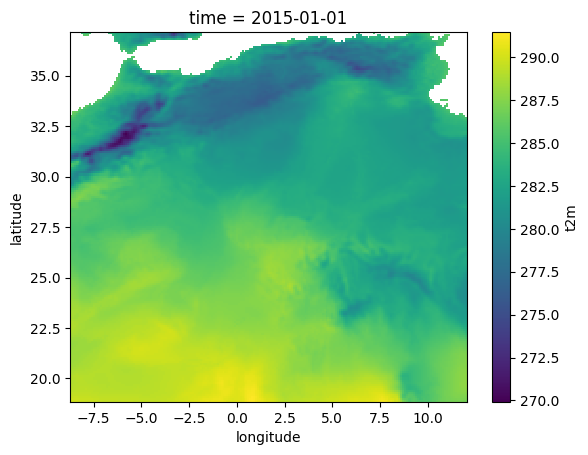

In [ ]:
ds["t2m"].isel(time=0).plot()

# **Retelechargement de la partie errone ( 2022 - 2024 )**

In [ ]:
import os
import xarray as xr
import numpy as np
# Dossiers
MNTH_DIR = os.path.join(DATA_DIR, "data_nc_corrected")

os.makedirs(MNTH_DIR, exist_ok=True)

# Les 7 variables accumulées
VARS_ACC = [
    "surface_latent_heat_flux",
    "surface_sensible_heat_flux",
    "surface_net_solar_radiation",
    "surface_net_thermal_radiation",
    "total_evaporation",
    "runoff",
    "total_precipitation"
]

# Télécharger les 12 mois de chaque année
for year in ["2022", "2023", "2024"]:

    target = os.path.join(
        MNTH_DIR,
        f"era5land_mnth_{year}_01-12.nc"
    )

    print(f"Téléchargement de {year}...")

    client.retrieve(
        "reanalysis-era5-land-monthly-means",
        {
            "product_type": [
                "monthly_averaged_reanalysis_by_hour_of_day"
            ],
            "variable": VARS_ACC,
            "year": [year],
            "month": [
                "01", "02", "03", "04", "05", "06",
                "07", "08", "09", "10", "11", "12"
            ],
            "time": ["00:00"],
            "area": AREA,
            "data_format": "netcdf",
            "download_format": "unarchived"
        },
        target
    )

    print(f"{year} terminé.")

Téléchargement de 2022...


2026-11-06 15:18:08,646 INFO Request ID is d0ea22c1-0e02-4a5b-a97f-922a0f60e54b
INFO:ecmwf.datastores.legacy_client:Request ID is d0ea22c1-0e02-4a5b-a97f-922a0f60e54b
2026-11-06 15:18:08,831 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


f9f24f864f53a1e87d5e23d00caf6fe2.nc:   0%|          | 0.00/6.32M [00:00<?, ?B/s]

2022 terminé.
Téléchargement de 2023...


2026-11-06 15:18:13,815 INFO Request ID is 5e4e7b8a-ae12-40d4-99b7-153bb265edef
INFO:ecmwf.datastores.legacy_client:Request ID is 5e4e7b8a-ae12-40d4-99b7-153bb265edef
2026-11-06 15:18:14,006 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


104a10872640670fb96b278de9f17422.nc:   0%|          | 0.00/6.34M [00:00<?, ?B/s]

2023 terminé.
Téléchargement de 2024...


2026-11-06 15:18:17,934 INFO Request ID is 70b29c31-ab83-40b5-88a3-b9f39a6370a4
INFO:ecmwf.datastores.legacy_client:Request ID is 70b29c31-ab83-40b5-88a3-b9f39a6370a4
2026-11-06 15:18:18,125 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


80b3ad53ef4fcabb0eb0397d014f9f23.nc:   0%|          | 0.00/6.34M [00:00<?, ?B/s]

2024 terminé.


Pour chaque année (2022, 2023 , 2024):
- Charger le fichier original qui contient les 12 variables.
- Charger le fichier MNTH qui contient les 7 variables accumulées corrigées.
- Conserver les 5 variables instantanées du fichier original : t2m, d2m, u10, v10, sp.
- Remplacer les 7 variables accumulées par celles du fichier MNTH : slhf, sshf, ssr, str, e, ro, tp.
- Enregistrer un nouveau fichier annuel complet contenant les 12 variables.

In [ ]:
import os
import xarray as xr
import numpy as np

# Dossiers
DATA_DIR = os.path.join(BASE, "data_nc")
MNTH_DIR = os.path.join(DATA_DIR, "data_nc_corrected")

# Dossier pour les fichiers annuels corrigés
ANNUAL_CORRECTED_DIR = os.path.join(DATA_DIR, "data_nc_annual_corrected")
os.makedirs(ANNUAL_CORRECTED_DIR, exist_ok=True)

# Variables accumulées à remplacer
VARS_ACC = ["slhf", "sshf", "ssr", "str", "e", "ro", "tp"]

# Années à corriger
CORRECTED_YEARS = [2022, 2023, 2024]

for year in CORRECTED_YEARS:

    print(f"\nCorrection de l'année {year}...")

    # Fichier original : 12 variables
    original_path = os.path.join(
        DATA_DIR,
        f"era5land_{year}_01-12.nc"
    )

    # Fichier MNTH : 7 variables corrigées
    mnth_path = os.path.join(
        MNTH_DIR,
        f"era5land_mnth_{year}_01-12.nc"
    )

    if not os.path.exists(original_path):
        raise FileNotFoundError(original_path)

    if not os.path.exists(mnth_path):
        raise FileNotFoundError(mnth_path)

    # Charger les deux fichiers
    with xr.open_dataset(original_path) as ds:
        ds_original = ds.load()

    with xr.open_dataset(mnth_path) as ds:
        ds_mnth = ds.load()

    # Vérifier les dimensions spatiales
    assert np.array_equal(
        ds_original.latitude.values,
        ds_mnth.latitude.values
    ), f"Latitudes différentes pour {year}"

    assert np.array_equal(
        ds_original.longitude.values,
        ds_mnth.longitude.values
    ), f"Longitudes différentes pour {year}"

    # Vérifier les variables disponibles
    for var in VARS_ACC:
        assert var in ds_original.data_vars, f"{var} absent du fichier original"
        assert var in ds_mnth.data_vars, f"{var} absent du fichier MNTH"

    # Copier le fichier original :
    # les 12 variables sont conservées
    ds_corrected = ds_original.copy(deep=True)

    # Remplacer uniquement les 7 variables accumulées
    for var in VARS_ACC:

        for month in range(1, 13):

            original_idx = np.where(
                ds_original.valid_time.dt.month.values == month
            )[0]

            mnth_idx = np.where(
                ds_mnth.valid_time.dt.month.values == month
            )[0]

            if len(original_idx) != 1 or len(mnth_idx) != 1:
                raise ValueError(
                    f"Problème de correspondance du mois {month}, année {year}"
                )

            # Remplacement des valeurs
            ds_corrected[var].values[original_idx[0], :, :] = (
                ds_mnth[var].isel(valid_time=mnth_idx[0]).values
            )

    # Vérifier que les 12 variables sont présentes
    assert len(ds_corrected.data_vars) == 12

    # Sauvegarder le fichier annuel corrigé
    output_path = os.path.join(
        ANNUAL_CORRECTED_DIR,
        f"era5land_{year}_01-12.nc"
    )

    ds_corrected.to_netcdf(output_path)

    print(f"Fichier annuel corrigé sauvegardé : {output_path}")

    ds_original.close()
    ds_mnth.close()
    ds_corrected.close()

print("\nLes trois fichiers annuels corrigés sont prêts.")


Correction de l'année 2022...
Fichier annuel corrigé sauvegardé : /content/drive/MyDrive/DataMining_Climat/data_nc/data_nc_annual_corrected/era5land_2022_01-12.nc

Correction de l'année 2023...
Fichier annuel corrigé sauvegardé : /content/drive/MyDrive/DataMining_Climat/data_nc/data_nc_annual_corrected/era5land_2023_01-12.nc

Correction de l'année 2024...
Fichier annuel corrigé sauvegardé : /content/drive/MyDrive/DataMining_Climat/data_nc/data_nc_annual_corrected/era5land_2024_01-12.nc

Les trois fichiers annuels corrigés sont prêts.


In [29]:
for year in [2022, 2023, 2024]:

    path = os.path.join(
        ANNUAL_CORRECTED_DIR,
        f"era5land_{year}_01-12.nc"
    )

    with xr.open_dataset(path) as ds:

        print(f"\nAnnée {year}")
        print("Dimensions :", ds.sizes)
        print("Variables :", list(ds.data_vars))
        print("Nombre de variables :", len(ds.data_vars))


Année 2022
Dimensions : Frozen({'valid_time': 12, 'latitude': 183, 'longitude': 208})
Variables : ['t2m', 'd2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']
Nombre de variables : 12

Année 2023
Dimensions : Frozen({'valid_time': 12, 'latitude': 183, 'longitude': 208})
Variables : ['t2m', 'd2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']
Nombre de variables : 12

Année 2024
Dimensions : Frozen({'valid_time': 12, 'latitude': 183, 'longitude': 208})
Variables : ['t2m', 'd2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']
Nombre de variables : 12


Fusionner les fichiers annuels

In [34]:
import os
import xarray as xr
import numpy as np

# Dossiers
DATA_DIR = os.path.join(BASE, "data_nc")

OUT_DIR_CORRECTED = os.path.join(BASE, "processed")
os.makedirs(OUT_DIR_CORRECTED, exist_ok=True)

YEARS = range(2015, 2027)
CORRECTED_YEARS = [2022, 2023, 2024]

files = []

# Sélectionner les fichiers annuels
for year in YEARS:

    if year in CORRECTED_YEARS:

        folder = ANNUAL_CORRECTED_DIR
        filename = f"era5land_{year}_01-12.nc"

    elif year == 2026:

        folder = DATA_DIR
        filename = "era5land_2026_01-08.nc"

    else:

        folder = DATA_DIR
        filename = f"era5land_{year}_01-12.nc"

    path = os.path.join(folder, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Fichier introuvable : {path}")

    files.append(path)

    print(f"{year} :", path)


# Charger les fichiers
datasets = []

for path in files:

    with xr.open_dataset(path) as ds:
        datasets.append(ds.load())


# Fusionner les années
ds_merged = xr.concat(
    datasets,
    dim="valid_time"
).sortby("valid_time")


# Vérifier les dates
times = ds_merged.valid_time.values

assert len(np.unique(times)) == len(times), \
    "Attention : des dates sont dupliquées !"

# Vérifier les dimensions
print("\nDimensions :", ds_merged.sizes)

print("\nVariables :", list(ds_merged.data_vars))

print("\nNombre total de mois :", len(times))


# Vérifier les NaN par variable
print("\nValeurs manquantes :")


# Sauvegarder le dataset fusionné
MERGED_PATH = os.path.join(
    OUT_DIR_CORRECTED,
    "era5land_merged_box_raw_corrected.nc"
)

ds_merged.to_netcdf(MERGED_PATH)

print("\nDataset sauvegardé :", MERGED_PATH)

2015 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2015_01-12.nc
2016 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2016_01-12.nc
2017 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2017_01-12.nc
2018 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2018_01-12.nc
2019 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2019_01-12.nc
2020 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2020_01-12.nc
2021 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2021_01-12.nc
2022 : /content/drive/MyDrive/DataMining_Climat/data_nc/data_nc_annual_corrected/era5land_2022_01-12.nc
2023 : /content/drive/MyDrive/DataMining_Climat/data_nc/data_nc_annual_corrected/era5land_2023_01-12.nc
2024 : /content/drive/MyDrive/DataMining_Climat/data_nc/data_nc_annual_corrected/era5land_2024_01-12.nc
2025 : /content/drive/MyDrive/DataMining_Climat/data_nc/era5land_2025_01-12.nc
2026 : /content/drive/MyDrive/DataMining_Climat/data_nc/

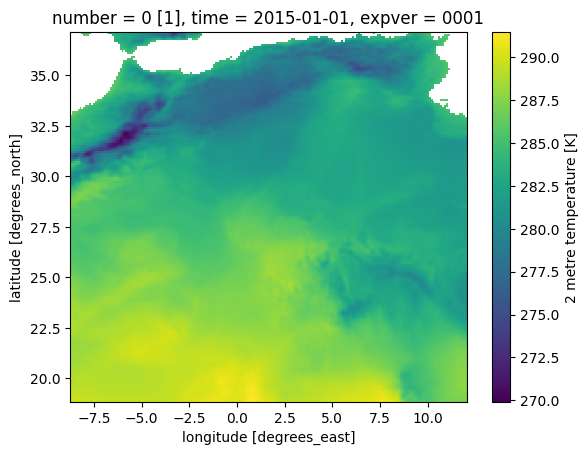

In [39]:
ds_merged = ds_merged.rename({"valid_time": "time"})
ds_merged["t2m"].isel(time=0).plot()

# **Applique le mask et resolution**

---



### Réduction de la résolution (facteur FACTOR)

La grille native ERA5-Land a une résolution de 0.1°. On l'agrège par blocs de `FACTOR × FACTOR` cellules voisines, chaque bloc étant remplacé par la moyenne de ses cellules (valeurs manquantes ignorées).

**Ordre des étapes :** tri des coordonnées → masque de l'Algérie sur la grille native 0.1° → agrégation. Le masque est appliqué avant l'agrégation pour que les blocs de bord ne soient moyennés que sur les cellules situées dans le pays.

La boîte de téléchargement `[N, W, S, E]` est calculée depuis le shapefile (limites arrondies vers l'extérieur à 0.1°).


en comentaire :


Climate dataset: Reduce the spatial resolution of the map by a factor of four by aggregating neighboring grid points

**Principe :** les données ERA5-Land ont une résolution native de 0,1° (environ 10 km), soit une grille de 181 × 211 points sur la zone englobant l'Algérie. Pour la réduire d'un facteur 2, on découpe la grille en **blocs de 2 x 2 points voisins** (4 points) et on remplace chaque bloc par **un seul point** dont la valeur est la **moyenne** des 16 points.

**Résultat :**
- Résolution : 0,1° → 0,4° (environ 40 km)
- Taille de la grille : 181 × 211 → 45 × 52 points
- Le nombre de points est divisé par 16, ce qui réduit le temps de calcul, et la moyenne lisse le bruit local.

In [35]:
SHP_PATH = "/content/drive/MyDrive/DataMining_Climat/dz_shp/dz.shp"
gdf = gpd.read_file(SHP_PATH)
print(gdf.crs)
print(gdf.shape)
dz = gdf.dissolve()

EPSG:4326
(1, 4)


applique sur la data apres correction

In [41]:
# si on veut data apres correction
ds = ds_merged

Cellules 0.1° dans l'Algérie : 21257
Avant : {'time': 140, 'latitude': 183, 'longitude': 208}
Après : {'time': 140, 'latitude': 92, 'longitude': 104}
Pas latitude  : [0.15 0.2 ]
Pas longitude : [0.2]
Points valides : 5425 / 9568


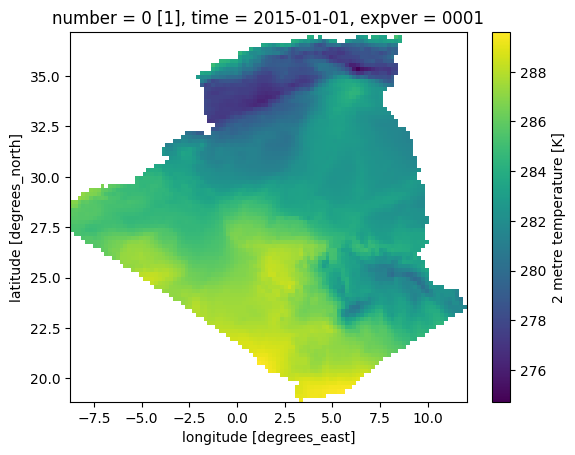

In [42]:
# 1) Tri croissant des coordonnées
ds = ds.sortby("latitude").sortby("longitude")

# 2) Masque Algérie sur la grille NATIVE 0.1° (centre de cellule dans le polygone)
lon2d, lat2d = np.meshgrid(ds.longitude.values, ds.latitude.values)
inside = contains_xy(geometry, lon2d, lat2d)
mask = xr.DataArray(inside,
                    coords={"latitude": ds.latitude, "longitude": ds.longitude},
                    dims=("latitude", "longitude"))
ds_masked = ds.where(mask)
print("Cellules 0.1° dans l'Algérie :", int(mask.sum()))

# 3) Réduction de résolution : moyenne des blocs FACTOR x FACTOR, NaN ignorés
print("Avant :", dict(ds_masked.sizes))
ds_dz = ds_masked.coarsen(latitude=FACTOR, longitude=FACTOR, boundary="pad").mean()
print("Après :", dict(ds_dz.sizes))

# 4) Contrôles
print("Pas latitude  :", np.unique(np.round(np.diff(ds_dz.latitude.values), 3)))
print("Pas longitude :", np.unique(np.round(np.diff(ds_dz.longitude.values), 3)))
t = ds_dz["t2m"].isel(time=0)
print("Points valides :", int(t.notnull().sum()), "/", t.size)


#ds_dz.to_netcdf(f"{OUT_DIR}/era5land_algeria_masked_x{FACTOR}.nc")
# si data apres correction:
ds_dz.to_netcdf(f"{OUT_DIR}/era5land_algeria_masked_x{FACTOR}_corrected.nc")
ds_dz["t2m"].isel(time=0).plot()

# **Aperçu du dataset final (Algérie, résolution ×4)**

Inspection du jeu de données après prétraitement : dimensions, période, résolution, premières lignes, types, statistiques et valeurs manquantes.

#### Investgation des deux datasetDispo

In [ ]:
# path du dataset initial
#PATH = f"{OUT_DIR}/era5land_algeria_masked_x2.nc"
PATH = f"{OUT_DIR}/era5land_algeria_masked_x2_corrected.nc"
ds_dz = xr.open_dataset(PATH)
print(ds_dz)
print(list(ds_dz.data_vars))

<xarray.Dataset> Size: 64MB
Dimensions:    (time: 140, latitude: 92, longitude: 104)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2015-01-01 2015-02-01 ... 2026-08-01
  * latitude   (latitude) float64 736B 18.95 19.15 19.35 ... 36.75 36.95 37.1
  * longitude  (longitude) float64 832B -8.65 -8.45 -8.25 ... 11.55 11.75 11.95
    number     int64 8B ...
    expver     (time) <U4 2kB ...
Data variables:
    t2m        (time, latitude, longitude) float32 5MB ...
    d2m        (time, latitude, longitude) float32 5MB ...
    slhf       (time, latitude, longitude) float32 5MB ...
    ssr        (time, latitude, longitude) float32 5MB ...
    str        (time, latitude, longitude) float32 5MB ...
    sshf       (time, latitude, longitude) float32 5MB ...
    ro         (time, latitude, longitude) float32 5MB ...
    e          (time, latitude, longitude) float32 5MB ...
    u10        (time, latitude, longitude) float32 5MB ...
    v10        (time, latitude, longitude) float32 5MB ..

**But 1:** comparer les dimensions, la période et les coordonnées (latitude et longitude) de nos deux datasets pour repérer leurs différences avant de choisir lequel utiliser.

In [ ]:
print(ds_dz.sizes)
print(ds_dz.latitude.values[[0,-1]])
print(ds_dz.longitude.values[[0,-1]])
"""
Frozen({'time': 140, 'latitude': 92, 'longitude': 104})
[18.95 37.1 ]
[-8.65 11.95]
"""

Frozen({'time': 140, 'latitude': 92, 'longitude': 104})
[18.95 37.1 ]
[-8.65 11.95]


"\nFrozen({'time': 140, 'latitude': 92, 'longitude': 104})\n[18.95 37.1 ]\n[-8.65 11.95]\n"

**But 3:** compter les points valides (hors NaN) dans chaque dataset au premier mois.

In [ ]:
t = ds["t2m"].isel(time=0)
print(f"avant mask et reolution: {int(t.notnull().sum())} valides / {t.size} au total")

t = ds_dz["t2m"].isel(time=0)
print(f"final : {int(t.notnull().sum())} valides / {t.size} au total")

NameError: name 'ds' is not defined